# V-COCO: EDA đơn giản

**Mục tiêu:** hiểu bộ dữ liệu trước khi training, theo 4 bước:
1. Dữ liệu gốc trông như thế nào (bao nhiêu ảnh, bao nhiêu người, 26 hành động, xem ảnh)
2. Map sang **6 nhãn đích**: `hold`, `ride`, `eat/drink`, `take_on_phone`, `work_on_computer`, `unknown`
3. Soi những chỗ **map đáng nghi**, có ảnh để tự kiểm tra
4. Lớp `hold` quá rộng: dẫn chứng bằng số liệu và đề xuất giới hạn

**Đặc điểm bộ này:**
- Nhãn gắn với **từng người** (có bbox người), và cho biết người đó tương tác với **vật nào** (có bbox vật).
- **Multi-label** (đa nhãn): 1 người có thể có nhiều hành động cùng lúc, ví dụ vừa `sit` vừa `hold` vừa `talk_on_phone`.

**Cách chạy:** nên chạy trên **Google Colab** (`Runtime → Run all`). Không cần chuẩn bị gì.

## Phần 0: Tải dữ liệu

**Lấy từ đâu?** V-COCO không có file ảnh riêng, nó là **nhãn bổ sung** cho ảnh của bộ COCO 2014:
1. **Nhãn hành động:** `git clone` repo GitHub `s-gupta/v-coco`, có sẵn file `data/vcoco/vcoco_*.json`
2. **Bbox người/vật:** tải file annotation của COCO 2014 (~250MB), chỉ giữ lại ảnh thuộc V-COCO, lưu thành `data/instances_vcoco_all_2014.json`
3. **Ảnh:** **không tải hết 13GB**. Khi cần xem ảnh nào thì tải ảnh đó qua đường link `coco_url`

⏱️ Trên Colab mất khoảng 1–2 phút. Chạy lại lần sau sẽ bỏ qua các bước đã làm.

In [7]:
!pip install -q pycocotools

zsh:1: command not found: pip


### 🧰 Công cụ dùng chung
Cell dưới đây định nghĩa **6 nhãn đích**, **bảng màu** và vài hàm vẽ. Cả 4 notebook dùng chung cell này, **chỉ cần chạy, không cần sửa**.

- `bang_dem(series)`: đếm số lượng và tỷ lệ % của từng nhãn
- `ve_cot(series, title)`: vẽ biểu đồ cột số lượng
- `show_grid(items, title)`: hiện một lưới ảnh, có thể kèm **bbox** (bounding box: khung chữ nhật đánh dấu vị trí người/vật trong ảnh)

In [8]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
random.seed(42); np.random.seed(42)

# 6 nhãn đích của bài toán
TARGET_CLASSES = ['hold', 'ride', 'eat/drink', 'take_on_phone', 'work_on_computer', 'unknown']
# Thứ tự ưu tiên khi 1 người có nhiều nhãn (priority rule): nhãn cụ thể thắng nhãn chung chung
PRIORITY = ['take_on_phone', 'work_on_computer', 'eat/drink', 'ride', 'hold', 'unknown']
CLASS_COLORS = {'hold': '#00C853', 'ride': '#2979FF', 'eat/drink': '#FF9100',
                'take_on_phone': '#D500F9', 'work_on_computer': '#00B8D4', 'unknown': '#9E9E9E'}


def bang_dem(series, ten_cot='nhãn'):
    """Bảng đếm: mỗi nhãn có bao nhiêu mẫu, chiếm bao nhiêu %."""
    vc = series.value_counts()
    return pd.DataFrame({ten_cot: vc.index, 'số lượng': vc.values,
                         'tỷ lệ %': (vc.values / vc.sum() * 100).round(1)})


def ve_cot(series, title, theo_6_lop=False, xoay=60):
    """Biểu đồ cột số lượng mỗi nhãn. theo_6_lop=True: giữ đúng thứ tự + màu của 6 lớp."""
    if theo_6_lop:
        vc = series.value_counts().reindex(TARGET_CLASSES, fill_value=0)
        colors = [CLASS_COLORS[c] for c in vc.index]
    else:
        vc = series.value_counts()
        colors = '#5C6BC0'
    fig, ax = plt.subplots(figsize=(max(6, 0.35 * len(vc) + 3), 4))
    ax.bar(vc.index.astype(str), vc.values, color=colors)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
    ax.set_title(title, weight='bold'); ax.set_ylabel('số lượng')
    ax.tick_params(axis='x', rotation=xoay)
    plt.tight_layout(); plt.show()


def show_grid(items, title='', ncols=6, size=2.6):
    """Hiện lưới ảnh.
    items: list các dict {'img': PIL.Image hoặc đường dẫn, 'title': chữ dưới ảnh,
                          'boxes': [(x1, y1, x2, y2, màu, chữ), ...]}  (boxes không bắt buộc)"""
    if len(items) == 0:
        print('⚠️ Không có ảnh nào để hiển thị'); return
    ncols = min(ncols, len(items))
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.8), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, it in zip(axes.ravel(), items):
        img = it.get('img')
        if isinstance(img, str):
            img = Image.open(img)
        if img is None:
            ax.set_title('(không tải được ảnh)', fontsize=8); continue
        ax.imshow(img)
        for (x1, y1, x2, y2, color, label) in it.get('boxes', []):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
            if label:
                ax.text(x1, y1, label, color='white', fontsize=7, va='bottom',
                        bbox=dict(facecolor=color, pad=1, edgecolor='none'))
        ax.set_title(it.get('title', ''), fontsize=8)
    fig.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout(); plt.show()

print('✅ Đã nạp công cụ dùng chung')

✅ Đã nạp công cụ dùng chung


In [11]:
import sys, json, zipfile, io, requests
from pycocotools.coco import COCO

if 'google.colab' in sys.modules:
    os.chdir('/content')
if not os.path.exists('v-coco'):
    os.system('git clone -q https://github.com/s-gupta/v-coco.git')
os.chdir('v-coco')

COCO_JSON = 'data/instances_vcoco_all_2014.json'
if not os.path.exists(COCO_JSON):
    print('📥 Đang tải annotation COCO 2014 (~250MB)...')
    os.system('curl -L -s -o annotations_trainval2014.zip http://images.cocodataset.org/annotations/annotations_trainval2014.zip')
    vcoco_ids = set(np.loadtxt('data/splits/vcoco_all.ids').astype(int))
    data = {'images': [], 'annotations': []}
    with zipfile.ZipFile('annotations_trainval2014.zip') as zf:
        for s in ['train2014', 'val2014']:
            d = json.load(zf.open(f'annotations/instances_{s}.json'))
            data['categories'] = d['categories']
            data['images'] += [im for im in d['images'] if im['id'] in vcoco_ids]
            data['annotations'] += [a for a in d['annotations'] if a['image_id'] in vcoco_ids]
    json.dump(data, open(COCO_JSON, 'w'))
    os.remove('annotations_trainval2014.zip')

coco = COCO(COCO_JSON)
print('✅ Đã tải xong annotation COCO cho', len(coco.imgs), 'ảnh V-COCO')

📥 Đang tải annotation COCO 2014 (~250MB)...
loading annotations into memory...
Done (t=0.90s)
creating index...
index created!
✅ Đã tải xong annotation COCO cho 10346 ảnh V-COCO


**Đọc nhãn V-COCO.** File `vcoco_<split>.json` có 26 phần tử, mỗi phần tử là 1 hành động. Trong mỗi hành động:
- `ann_id`: id của từng người (dùng để lấy bbox người trong COCO)
- `label`: 1 nếu người đó làm hành động này, 0 nếu không
- `role_object_id`: id của **vật** mà người đó tương tác (ví dụ vật được cầm), 0 nếu không có

Ta gộp lại thành bảng: **mỗi dòng = 1 người**, cột `actions` là danh sách các hành động của người đó.

In [12]:
def load_vcoco(split):
    data = json.load(open(f'data/vcoco/{split}.json'))
    for a in data:
        a['role_object_id'] = np.array(a['role_object_id']).reshape(len(a['role_name']), -1).T
        a['label'] = np.array(a['label']).ravel()
    return data

def ten_vat(ann_id):
    """Từ id của vật → tên loại vật (ví dụ 'cell_phone'). Không có vật thì trả về ''."""
    ann_id = int(ann_id)
    if ann_id == 0 or ann_id not in coco.anns:
        return ''
    return coco.cats[coco.anns[ann_id]['category_id']]['name'].replace(' ', '_')

rows = []
for split in ['vcoco_trainval', 'vcoco_test']:
    data = load_vcoco(split)
    ann_ids = np.array(data[0]['ann_id']).ravel()
    image_ids = np.array(data[0]['image_id']).ravel()
    for i in range(len(ann_ids)):
        actions, vat, vat_id = [], {}, {}
        for a in data:
            if a['label'][i] == 1:
                actions.append(a['action_name'])
                if len(a['role_name']) > 1:          # cột 0 là người, cột 1 là vật/dụng cụ đầu tiên
                    vat_id[a['action_name']] = int(a['role_object_id'][i, 1])
                    vat[a['action_name']] = ten_vat(vat_id[a['action_name']])
        x, y, w, h = coco.anns[int(ann_ids[i])]['bbox']
        rows.append({'split': split, 'image_id': int(image_ids[i]), 'ann_id': int(ann_ids[i]),
                     'bbox': (int(x), int(y), int(x + w), int(y + h)), 'actions': actions, 'objects': vat, 'object_ids': vat_id})

df = pd.DataFrame(rows)
df['image_url'] = df['image_id'].apply(lambda i: coco.imgs[i]['coco_url'])
ACTIONS = [a['action_name'] for a in data]
print(f'✅ Đã đọc xong: {df.image_id.nunique()} ảnh, {len(df)} người, {len(ACTIONS)} hành động gốc')
df.head()

✅ Đã đọc xong: 10346 ảnh, 16199 người, 26 hành động gốc


,split,image_id,ann_id,bbox,actions,objects,object_ids,image_url
0,vcoco_trainval,226162,183192,"(154, 71, 312, 395)","[hold, stand, walk, look, carry]","{'hold': 'surfboard', 'look': '', 'carry': 'su...","{'hold': 647240, 'look': 0, 'carry': 647240}",http://images.cocodataset.org/train2014/COCO_t...
1,vcoco_trainval,210751,183193,"(272, 102, 489, 371)","[hold, sit, drink]","{'hold': 'cup', 'sit': 'couch', 'drink': 'cup'}","{'hold': 673832, 'sit': 98040, 'drink': 673832}",http://images.cocodataset.org/train2014/COCO_t...
2,vcoco_trainval,433398,183205,"(291, 85, 639, 471)","[hold, sit, ride, smile]","{'hold': '', 'sit': '', 'ride': 'boat'}","{'hold': 0, 'sit': 0, 'ride': 2056004}",http://images.cocodataset.org/train2014/COCO_t...
3,vcoco_trainval,54995,183272,"(110, 2, 639, 417)","[hold, sit, look, eat]","{'hold': 'fork', 'sit': '', 'look': 'fork', 'e...","{'hold': 1516215, 'sit': 0, 'look': 1516215, '...",http://images.cocodataset.org/train2014/COCO_t...
4,vcoco_trainval,78578,183314,"(123, 44, 283, 443)","[hold, stand, look, cut, smile]","{'hold': 'knife', 'look': 'knife', 'cut': 'kni...","{'hold': 694458, 'look': 694458, 'cut': 694458}",http://images.cocodataset.org/train2014/COCO_t...


In [13]:
# Tải ảnh COCO theo đường link (có lưu lại để lần sau không phải tải lại)
os.makedirs('coco_images', exist_ok=True)

def lay_anh(image_id):
    path = f'coco_images/{image_id}.jpg'
    if not os.path.exists(path):
        try:
            r = requests.get(coco.imgs[image_id]['coco_url'], timeout=15)
            open(path, 'wb').write(r.content)
        except Exception:
            return None
    return Image.open(path)

def item_nguoi(r, title, color='#00C853', label=''):
    """Tạo 1 ô ảnh cho show_grid: ảnh + bbox người (+ bbox vật hold nếu có)."""
    boxes = [(*r.bbox, color, label)]
    hb = getattr(r, 'hold_bbox', None)
    if isinstance(hb, tuple):
        boxes.append((*hb, '#FF9100', 'vật'))
    return {'img': lay_anh(r.image_id), 'title': title, 'boxes': boxes}

## Phần 1: Dữ liệu gốc trông như thế nào?

**Mục tiêu:** biết có bao nhiêu ảnh, bao nhiêu người, mỗi hành động có bao nhiêu người.
**Cách đọc kết quả:** vì là multi-label nên **tổng số theo hành động > số người**. Cột chênh lệch nhiều thì dữ liệu *mất cân bằng*.

                so_anh  so_nguoi
split                           
vcoco_test        4946      7768
vcoco_trainval    5400      8431

Số người KHÔNG có hành động nào : 166
Số người có ≥2 hành động        : 14346


,hành động gốc,số lượng,tỷ lệ %
0,stand,8716,18.7
1,hold,7609,16.4
2,look,7172,15.4
3,sit,3905,8.4
4,smile,2960,6.4
5,jump,1335,2.9
6,run,1309,2.8
7,walk,1253,2.7
8,eat,1198,2.6
9,ride,1044,2.2


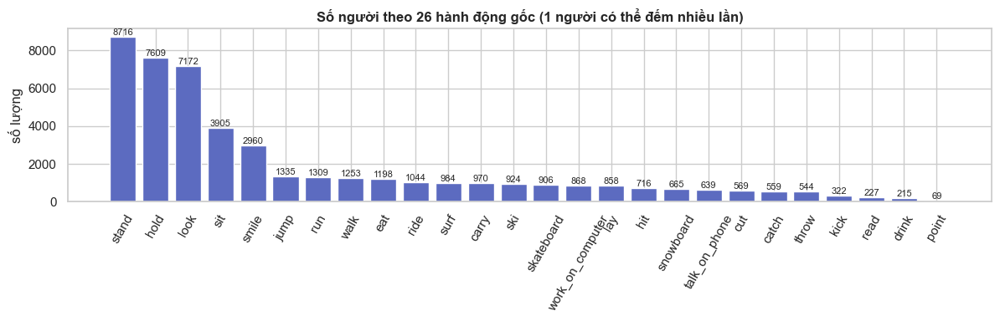

In [14]:
print(df.groupby('split').agg(so_anh=('image_id', 'nunique'), so_nguoi=('ann_id', 'size')))
print()
print('Số người KHÔNG có hành động nào :', (df['actions'].str.len() == 0).sum())
print('Số người có ≥2 hành động        :', (df['actions'].str.len() >= 2).sum())

tung_hanh_dong = df.explode('actions')['actions'].dropna()
display(bang_dem(tung_hanh_dong, 'hành động gốc'))
ve_cot(tung_hanh_dong, 'Số người theo 26 hành động gốc (1 người có thể đếm nhiều lần)')

           width     height
min   128.000000  145.00000
mean  577.880244  481.53122
max   640.000000  640.00000


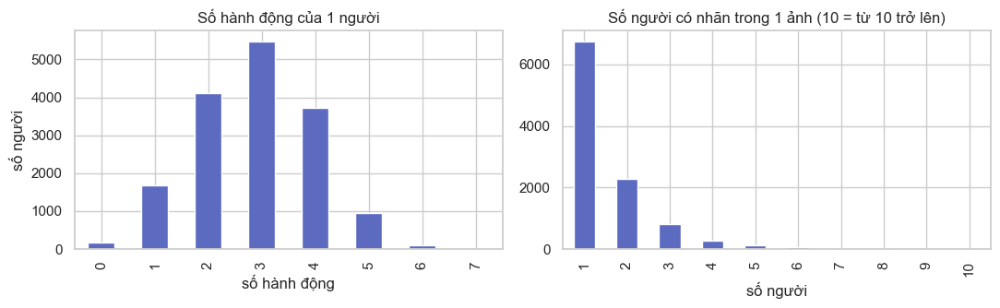

In [15]:
anh = pd.DataFrame([coco.imgs[i] for i in df.image_id.unique()])
print(anh[['width', 'height']].describe().loc[['min', 'mean', 'max']])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df['actions'].str.len().value_counts().sort_index().plot.bar(ax=axes[0], color='#5C6BC0')
axes[0].set_title('Số hành động của 1 người'); axes[0].set_xlabel('số hành động'); axes[0].set_ylabel('số người')
df.groupby('image_id').size().clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[1], color='#5C6BC0')
axes[1].set_title('Số người có nhãn trong 1 ảnh (10 = từ 10 trở lên)'); axes[1].set_xlabel('số người')
plt.tight_layout(); plt.show()

**Xem ảnh mẫu:** mỗi hành động 1 người (khung xanh là người mang nhãn đó). Ảnh được tải từ server COCO nên lần đầu hơi chậm.

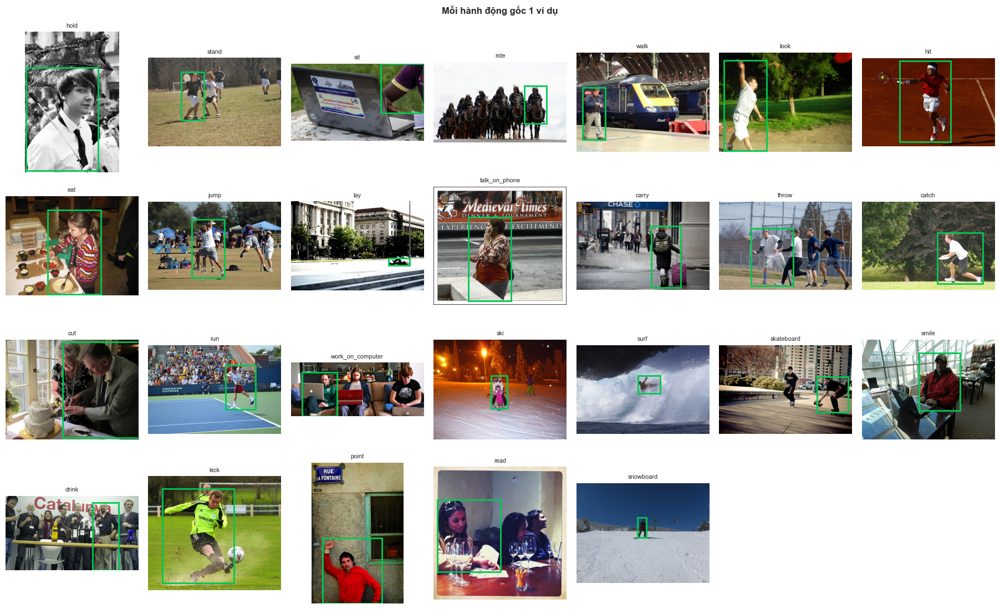

In [16]:
items = []
for act in ACTIONS:
    sub = df[df['actions'].apply(lambda a: act in a)]
    r = sub.sample(1, random_state=42).iloc[0]
    items.append(item_nguoi(r, act))
show_grid(items, 'Mỗi hành động gốc 1 ví dụ', ncols=7)

📝 **Nhận xét của bạn:** *(ví dụ: nhiều người trong ảnh, hành động nhỏ khó thấy…)*

📌 **Kết luận phần 1**
- Khoảng 10,3 nghìn ảnh và 16,2 nghìn người (trainval 8.431 + test 7.768).
- Là multi-label: khoảng 89% người có từ 2 hành động trở lên (thường là 1 tư thế như `stand`/`sit` cộng 1 tương tác).
- Nhãn gắn với **từng người** có bbox, nên có thể crop người ra để phân loại.

## Phần 2: Map sang 6 nhãn đích

**Cách làm:** bảng tra *hành động gốc → nhãn đích*. Vì 1 người có nhiều hành động, dùng **priority rule**: chọn nhãn đứng trước trong
`take_on_phone > work_on_computer > eat/drink > ride > hold > unknown`.

**Vì sao cần priority rule?** Người nghe điện thoại gần như luôn **cầm** điện thoại, nên có cả `talk_on_phone` và `hold`. Ta muốn nhãn **cụ thể hơn** thắng.

In [17]:
MAPPING = {
    'talk_on_phone': 'take_on_phone',
    'work_on_computer': 'work_on_computer',
    'eat': 'eat/drink', 'drink': 'eat/drink',
    'ride': 'ride',
    'hold': 'hold',
}   # 20 hành động còn lại → unknown

def map_nguoi(actions):
    cac_nhan = [MAPPING.get(a, 'unknown') for a in actions] or ['unknown']
    return min(cac_nhan, key=PRIORITY.index)

df['target_label'] = df['actions'].apply(map_nguoi)
df['original_label'] = df['actions'].apply(lambda a: '+'.join(a) if a else '(không có)')
pd.DataFrame({'hành động gốc': ACTIONS, 'nhãn đích': [MAPPING.get(a, 'unknown') for a in ACTIONS]})

,hành động gốc,nhãn đích
0,hold,hold
1,stand,unknown
2,sit,unknown
3,ride,ride
4,walk,unknown
5,look,unknown
6,hit,unknown
7,eat,eat/drink
8,jump,unknown
9,lay,unknown


,nhãn đích,số lượng,tỷ lệ %
0,unknown,7251,44.8
1,hold,5125,31.6
2,eat/drink,1334,8.2
3,ride,999,6.2
4,work_on_computer,851,5.3
5,take_on_phone,639,3.9


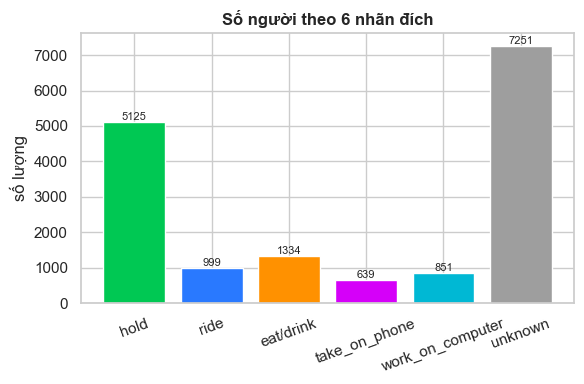

In [18]:
display(bang_dem(df['target_label'], 'nhãn đích'))
ve_cot(df['target_label'], 'Số người theo 6 nhãn đích', theo_6_lop=True, xoay=20)

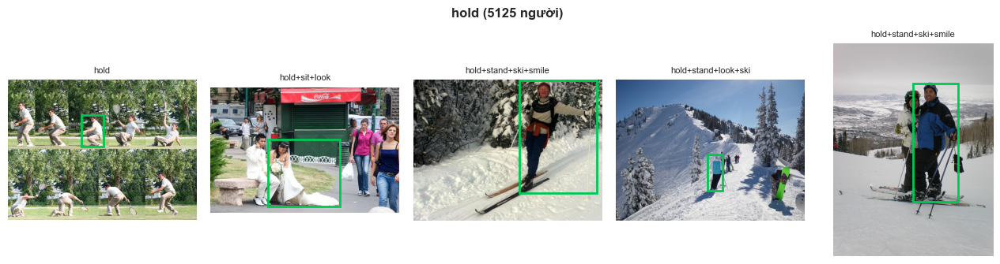

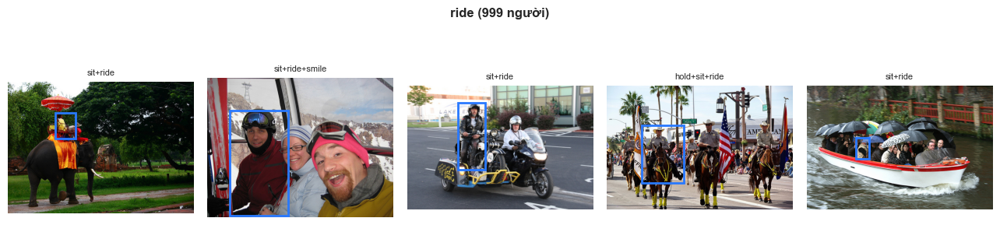

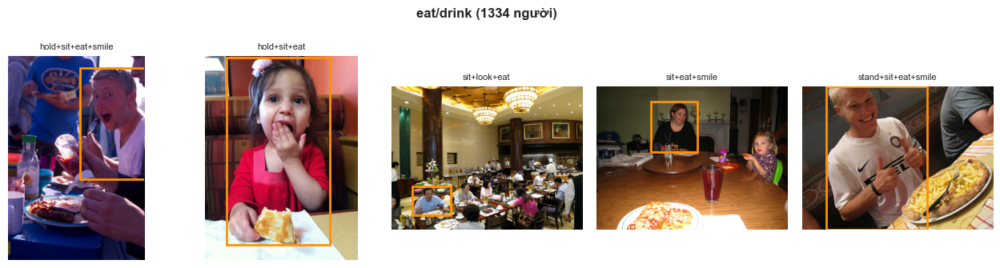

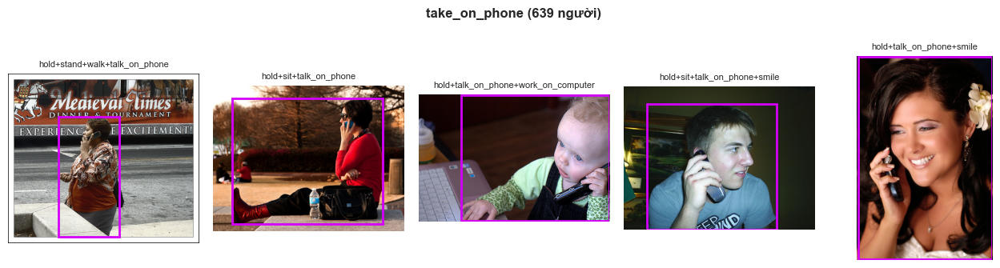

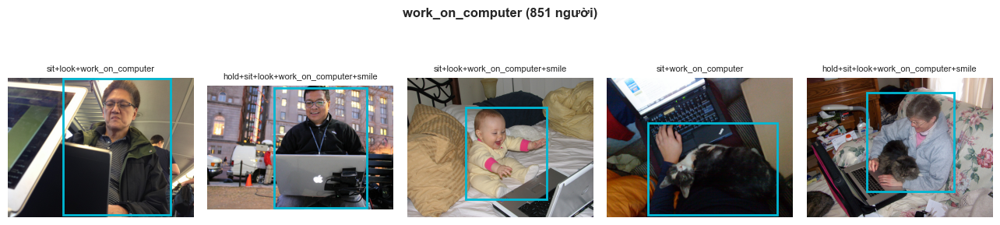

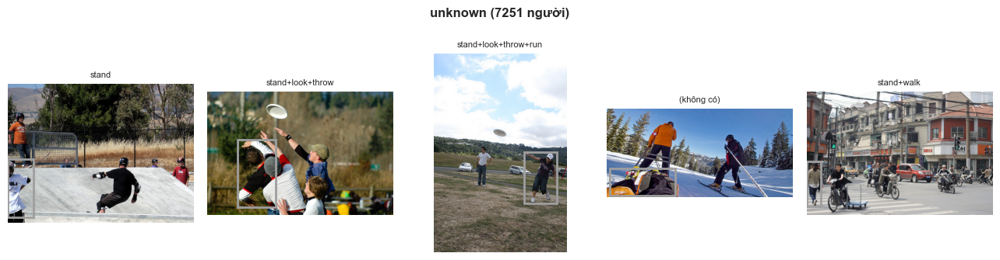

In [19]:
for cls in TARGET_CLASSES:
    sub = df[df['target_label'] == cls]
    rows = sub.sample(min(5, len(sub)), random_state=42)
    show_grid([item_nguoi(r, r.original_label[:40], CLASS_COLORS[cls]) for r in rows.itertuples()],
              f'{cls} ({len(sub)} người)', ncols=5)

In [20]:
df['hold_object'] = df.apply(lambda r: r.objects.get('hold', '') if r.target_label == 'hold' else '', axis=1)
df['hold_verb'] = df['target_label'].apply(lambda t: 'hold' if t == 'hold' else '')

def bbox_vat(r):
    """bbox của vật đang được cầm (chỉ với người thuộc hold) → (x1, y1, x2, y2), không có thì None."""
    ann_id = r.object_ids.get('hold', 0)
    if r.target_label != 'hold' or ann_id not in coco.anns:
        return None
    x, y, w, h = coco.anns[ann_id]['bbox']
    return (int(x), int(y), int(x + w), int(y + h))

df['hold_bbox'] = df.apply(bbox_vat, axis=1)

df_labels = pd.DataFrame({
    'dataset': 'v_coco',
    'image': df['image_url'],
    'person_bbox': df['bbox'].apply(lambda b: ','.join(map(str, b))),
    'object_bbox': df['hold_bbox'].apply(lambda b: ','.join(map(str, b)) if b else ''),
    'original_label': df['original_label'],
    'target_label': df['target_label'],
    'hold_object': df['hold_object'],
    'hold_verb': df['hold_verb'],
    'split': df['split'],
})
print('Đã tạo df_labels:', df_labels.shape, '(mỗi dòng = 1 người)')

Đã tạo df_labels: (16199, 9) (mỗi dòng = 1 người)


📌 **Kết luận phần 2**
- `unknown` ≈ 45% và `hold` ≈ 32%: hai lớp này chiếm gần 80%.
- `take_on_phone` (~4%), `work_on_computer` (~5%), `ride` (~6%) là các lớp thiểu số.

## Phần 3: Những chỗ map đáng nghi

### 3.1 Các hành động hay đi cùng nhau (co-occurrence)
**Cách đọc bảng nhiệt:** ô ở hàng **A**, cột **B** = *trong số người làm A, bao nhiêu % cũng làm B*. Ô càng đậm thì A và B càng hay đi cùng nhau, và priority rule càng quan trọng.

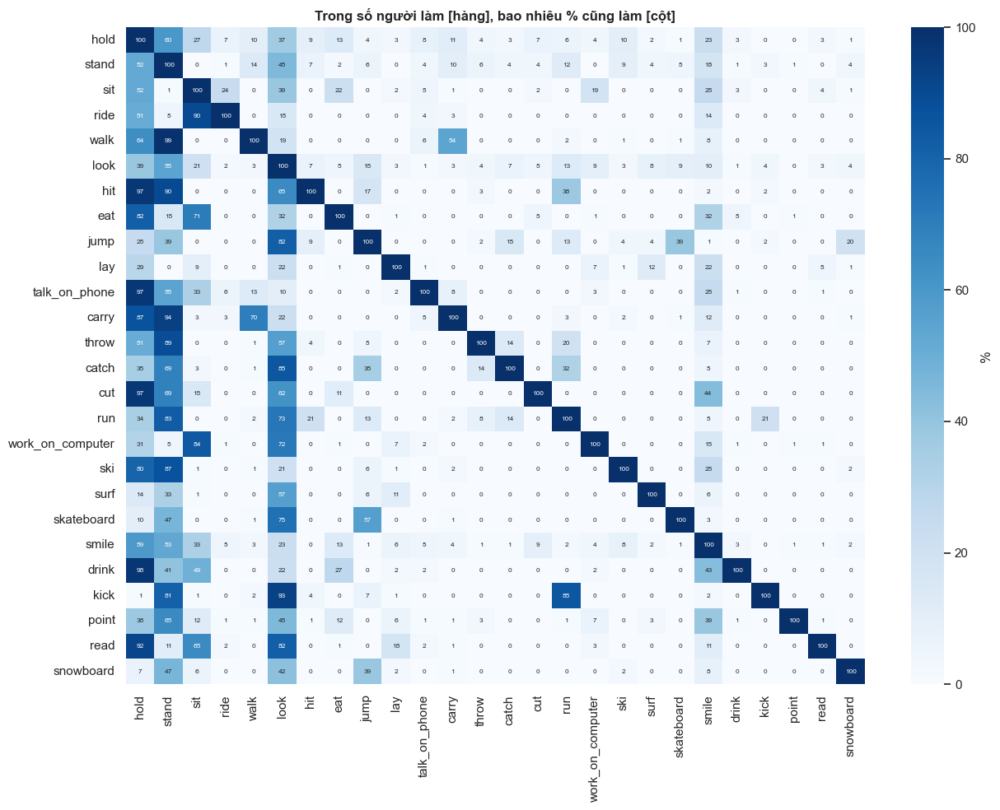

talk_on_phone     : 97% cũng có nhãn hold
work_on_computer  : 31% cũng có nhãn hold
eat               : 82% cũng có nhãn hold
drink             : 98% cũng có nhãn hold
ride              : 51% cũng có nhãn hold


In [21]:
onehot = pd.DataFrame([{a: int(a in acts) for a in ACTIONS} for acts in df['actions']])
co = (onehot.T @ onehot)
co_pct = (co.div(np.diag(co), axis=0) * 100).round(0)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(co_pct, cmap='Blues', annot=True, fmt='.0f', annot_kws={'size': 6}, cbar_kws={'label': '%'}, ax=ax)
ax.set_title('Trong số người làm [hàng], bao nhiêu % cũng làm [cột]', weight='bold')
plt.tight_layout(); plt.show()

for a in ['talk_on_phone', 'work_on_computer', 'eat', 'drink', 'ride']:
    print(f'{a:18s}: {co_pct.loc[a, "hold"]:.0f}% cũng có nhãn hold')

### 3.2 Danh sách nghi ngờ (kèm ảnh)
Mỗi mục có *lý do*, *số người bị ảnh hưởng*, *6 ảnh*. Xem xong, trả lời **Giữ / Bỏ / Đổi lớp?**

🔎 Cầm điện thoại/laptop nhưng chỉ có nhãn hold  |  137 người
   Lý do nghi ngờ: Người đang cầm điện thoại/laptop, rất có thể đang dùng, nhưng thiếu nhãn talk_on_phone/work_on_computer.


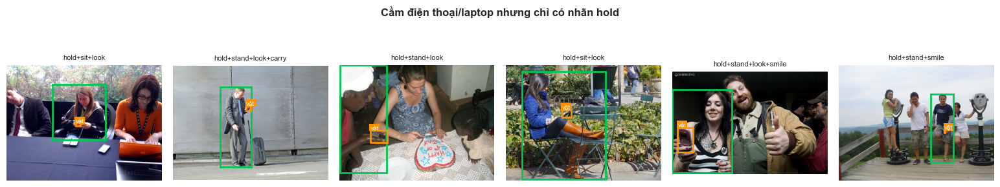

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 carry (mang vác) → unknown  |  116 người
   Lý do nghi ngờ: HICO-DET map carry → hold, còn ở đây carry → unknown. Hai bộ KHÔNG nhất quán.


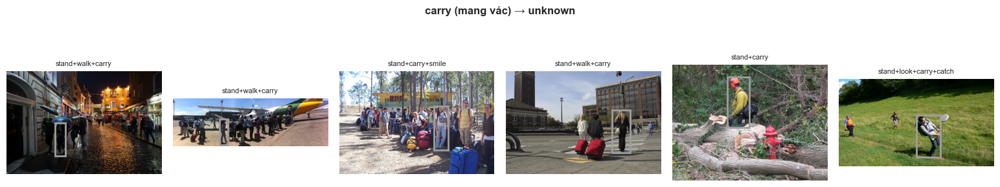

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 read (đọc) → unknown  |  17 người
   Lý do nghi ngờ: PASCAL VOC map reading → hold, còn ở đây read → unknown. KHÔNG nhất quán.


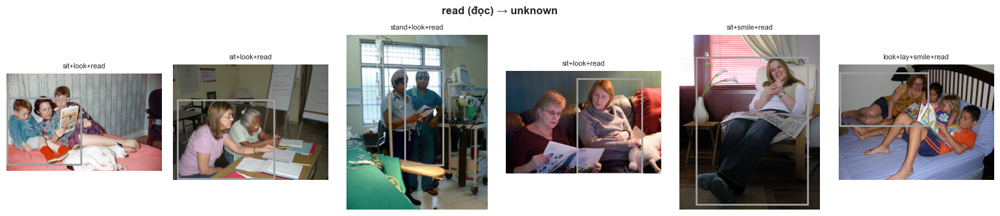

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 unknown: người KHÔNG có hành động nào  |  166 người
   Lý do nghi ngờ: Người này thật sự không làm gì, hay chỉ là bị thiếu nhãn?


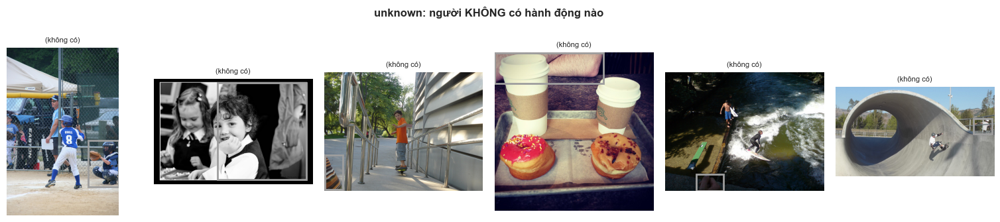

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 unknown: người chơi thể thao với đồ vật  |  3341 người
   Lý do nghi ngờ: Có cầm/dùng vật (vợt, gậy, ván…), dễ bị model nhầm với hold.


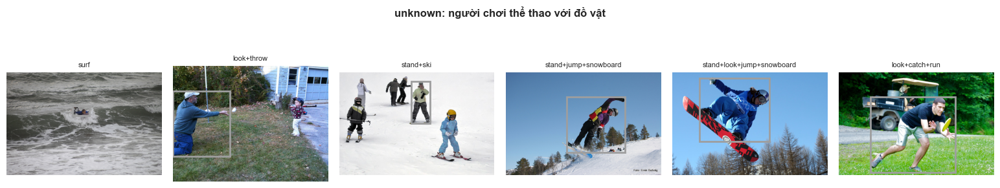

   ❓ Giữ / Bỏ / Đổi lớp?


In [22]:
PHONE_PC = {'cell_phone', 'laptop', 'keyboard', 'mouse'}
POSE_ONLY = {'stand', 'sit', 'walk', 'run', 'smile', 'look', 'point', 'lay', 'jump'}

NGHI_NGO = [
    {'ten': 'Cầm điện thoại/laptop nhưng chỉ có nhãn hold',
     'dieu_kien': lambda r: r.target_label == 'hold' and r.objects.get('hold', '') in PHONE_PC,
     'ly_do': 'Người đang cầm điện thoại/laptop, rất có thể đang dùng, nhưng thiếu nhãn talk_on_phone/work_on_computer.'},
    {'ten': 'carry (mang vác) → unknown',
     'dieu_kien': lambda r: 'carry' in r.actions and r.target_label == 'unknown',
     'ly_do': 'HICO-DET map carry → hold, còn ở đây carry → unknown. Hai bộ KHÔNG nhất quán.'},
    {'ten': 'read (đọc) → unknown',
     'dieu_kien': lambda r: 'read' in r.actions and r.target_label == 'unknown',
     'ly_do': 'PASCAL VOC map reading → hold, còn ở đây read → unknown. KHÔNG nhất quán.'},
    {'ten': 'unknown: người KHÔNG có hành động nào',
     'dieu_kien': lambda r: len(r.actions) == 0,
     'ly_do': 'Người này thật sự không làm gì, hay chỉ là bị thiếu nhãn?'},
    {'ten': 'unknown: người chơi thể thao với đồ vật',
     'dieu_kien': lambda r: r.target_label == 'unknown' and any(a in r.actions for a in ['hit', 'kick', 'throw', 'catch', 'ski', 'surf', 'skateboard', 'snowboard']),
     'ly_do': 'Có cầm/dùng vật (vợt, gậy, ván…), dễ bị model nhầm với hold.'},
]

for ng in NGHI_NGO:
    sub = df[df.apply(ng['dieu_kien'], axis=1)]
    print('=' * 100)
    print(f"🔎 {ng['ten']}  |  {len(sub)} người")
    print(f"   Lý do nghi ngờ: {ng['ly_do']}")
    rows = sub.sample(min(6, len(sub)), random_state=1)
    show_grid([item_nguoi(r, r.original_label[:40], CLASS_COLORS[r.target_label]) for r in rows.itertuples()], ng['ten'])
    print('   ❓ Giữ / Bỏ / Đổi lớp?')

### 3.2b Xem ảnh theo NHÃN GỐC: 4 câu hỏi cụ thể
Mỗi ô ảnh có **khung màu** là người, **khung cam** là vật; tiêu đề ghi **tên vật | tất cả hành động gốc** của người đó (bỏ bớt `stand/sit/look/smile` cho gọn).

1. Nhãn `hold` mà vật là **đồ thể thao**: có thêm hành động gốc nào (`hit`, `surf`, `ski`…)?
2. **137 người** chỉ `hold` điện thoại/laptop mà không có `talk_on_phone`/`work_on_computer`.
3. Có ai **cầm đồ ăn, đồ uống** mà bị vào `hold` (không phải `eat/drink`) không?
4. Có ai **có máy tính** (laptop, keyboard, mouse) mà **không** thuộc `work_on_computer` không?

In [23]:
POSE = {'stand', 'sit', 'walk', 'look', 'smile', 'lay'}   # tư thế, bỏ khi hiện tiêu đề
SPORT_OBJECTS = {'tennis_racket', 'surfboard', 'frisbee', 'baseball_bat', 'skis', 'snowboard',
                 'skateboard', 'sports_ball', 'baseball_glove', 'kite'}
PHONE_PC = {'cell_phone', 'laptop', 'keyboard', 'mouse'}
FOOD = {'pizza', 'donut', 'hot_dog', 'sandwich', 'cake', 'banana', 'broccoli', 'carrot', 'apple', 'orange'}
DRINK_CONTAINER = {'cup', 'wine_glass', 'bottle', 'bowl'}
COMPUTER = {'laptop', 'keyboard', 'mouse'}

def vat_cua(r, tap_vat):
    """Tìm vật thuộc tap_vat trong các hành động của người r → (tên hành động, tên vật, bbox vật). Không có thì None."""
    for act, ten in r.objects.items():
        if ten in tap_vat:
            ann_id = r.object_ids.get(act, 0)
            if ann_id in coco.anns:
                x, y, w, h = coco.anns[ann_id]['bbox']
                return act, ten, (int(x), int(y), int(x + w), int(y + h))
            return act, ten, None
    return None

def item_goc(r, tap_vat, color):
    act, ten, bb = vat_cua(r, tap_vat)
    hd = '+'.join(a for a in r.actions if a not in POSE) or '(chỉ tư thế)'
    boxes = [(*r.bbox, color, '')]
    if bb:
        boxes.append((*bb, '#FF9100', ten))
    return {'img': lay_anh(r.image_id), 'title': f'{ten} | {hd}'[:48], 'boxes': boxes}

def xem_nhom(sub, tap_vat, ten, color, n=12, seed=1):
    print('=' * 100)
    print(f'🔎 {ten}  |  {len(sub)} người')
    if len(sub) == 0:
        return
    rows = sub.sample(min(n, len(sub)), random_state=seed)
    show_grid([item_goc(r, tap_vat, color) for r in rows.itertuples()], ten)

Người hold đồ thể thao: 1941 / 5125 người hold
Trong đó có hành động gốc khác ngoài hold + tư thế: 84%



,vật,số người,hành động gốc đi kèm nhiều nhất
0,tennis_racket,526,"hit (457), run (233), jump (118)"
1,surfboard,324,"carry (208), surf (87), jump (7)"
2,frisbee,323,"catch (146), throw (131), run (83)"
3,baseball_bat,222,"hit (190), run (33), carry (2)"
4,snowboard,114,"snowboard (36), jump (30), carry (21)"
5,skis,106,"ski (58), carry (14), jump (8)"
6,baseball_glove,104,"throw (43), catch (34), run (20)"
7,sports_ball,98,"throw (67), run (17), catch (7)"
8,skateboard,96,"skateboard (51), jump (41), carry (13)"
9,kite,28,"run (13), carry (9), jump (2)"


🔎 hold + tennis_racket  |  526 người


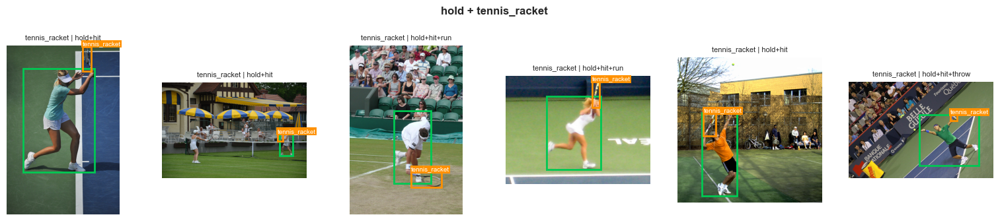

🔎 hold + surfboard  |  324 người


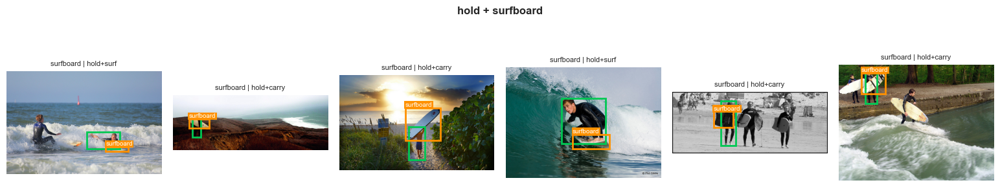

🔎 hold + frisbee  |  323 người


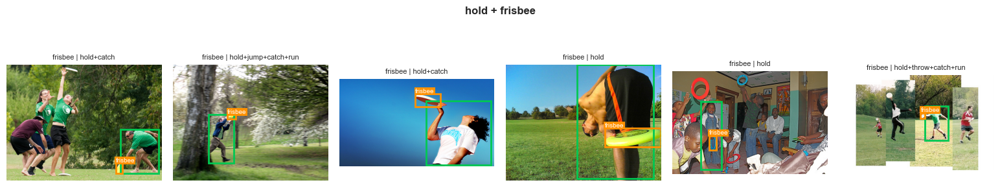

🔎 hold + baseball_bat  |  222 người


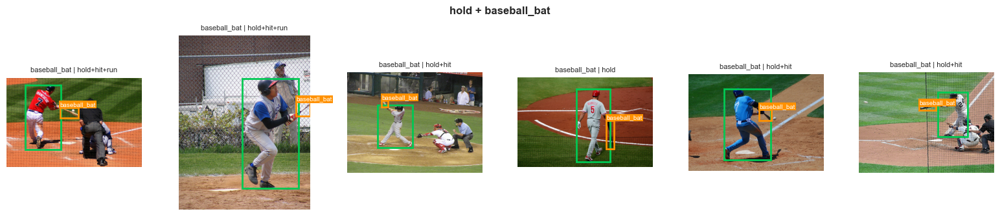

In [24]:
# 1) hold + đồ thể thao: hành động gốc đi kèm là gì?
hold_the_thao = df[(df.target_label == 'hold') & df.objects.apply(lambda o: o.get('hold', '') in SPORT_OBJECTS)].copy()
hold_the_thao['vat'] = hold_the_thao.objects.apply(lambda o: o['hold'])
hold_the_thao['hanh_dong_them'] = hold_the_thao.actions.apply(lambda a: [x for x in a if x != 'hold' and x not in POSE])

print(f'Người hold đồ thể thao: {len(hold_the_thao)} / {(df.target_label == "hold").sum()} người hold')
print(f'Trong đó có hành động gốc khác ngoài hold + tư thế: {(hold_the_thao.hanh_dong_them.apply(len) > 0).mean():.0%}\n')

# Bảng: mỗi vật thể thao đi kèm hành động gốc nào nhiều nhất
bang = []
for vat, g in hold_the_thao.groupby('vat'):
    dem = pd.Series([x for l in g.hanh_dong_them for x in l]).value_counts()
    bang.append({'vật': vat, 'số người': len(g), 'hành động gốc đi kèm nhiều nhất': ', '.join(f'{k} ({v})' for k, v in dem.head(3).items())})
display(pd.DataFrame(bang).sort_values('số người', ascending=False).reset_index(drop=True))

# Ảnh: 6 người cho mỗi vật phổ biến nhất
for vat in hold_the_thao.vat.value_counts().head(4).index:
    xem_nhom(hold_the_thao[hold_the_thao.vat == vat], {vat}, f'hold + {vat}', CLASS_COLORS['hold'], n=6)

**2. Cầm điện thoại/laptop mà thiếu nhãn dùng**

Vật đang cầm: {'cell_phone': 126, 'laptop': 9, 'mouse': 2}
🔎 Cầm điện thoại/laptop nhưng chỉ có nhãn hold  |  137 người


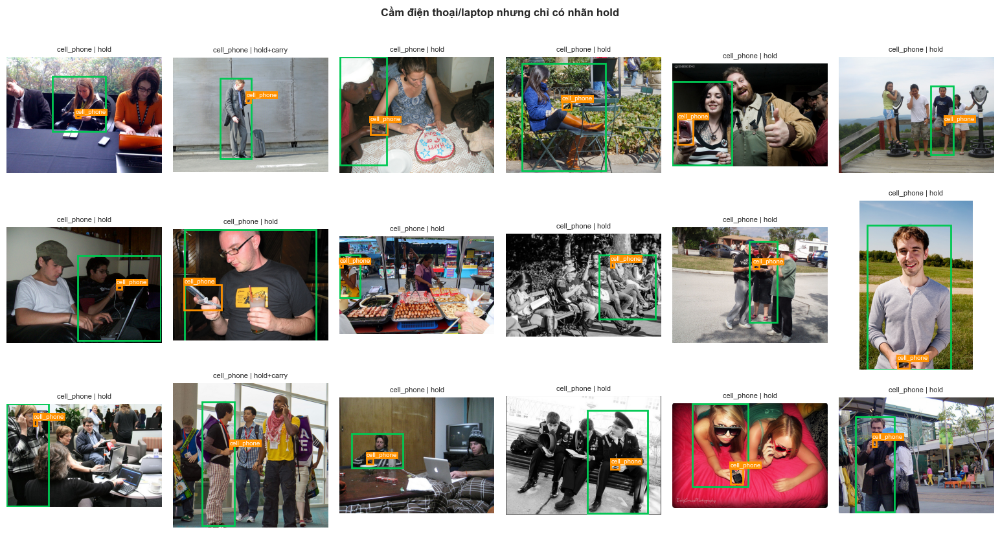

In [25]:
# 2) Người chỉ hold điện thoại / laptop, không có talk_on_phone / work_on_computer
cam_dt_pc = df[(df.target_label == 'hold') & df.objects.apply(lambda o: o.get('hold', '') in PHONE_PC)]
print('Vật đang cầm:', cam_dt_pc.objects.apply(lambda o: o['hold']).value_counts().to_dict())
xem_nhom(cam_dt_pc, PHONE_PC, 'Cầm điện thoại/laptop nhưng chỉ có nhãn hold', CLASS_COLORS['hold'], n=18)

**3. Cầm đồ ăn/đồ uống nhưng vào `hold`**

Đồ ăn  : {'pizza': 15, 'banana': 14, 'cake': 14, 'apple': 3, 'hot_dog': 2, 'broccoli': 1, 'carrot': 1, 'donut': 1}
Đồ uống: {'cup': 36, 'wine_glass': 26, 'bottle': 19, 'bowl': 5}
🔎 hold nhưng đang cầm ĐỒ ĂN  |  51 người


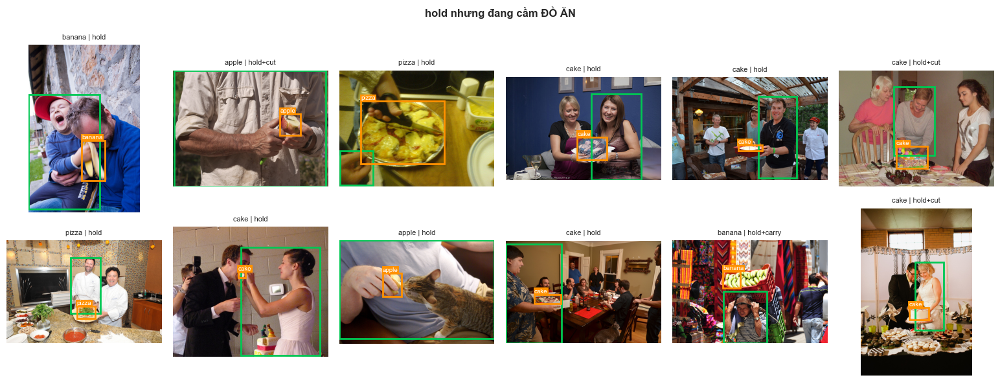

🔎 hold nhưng đang cầm ĐỒ UỐNG / ĐỒ ĐỰNG  |  86 người


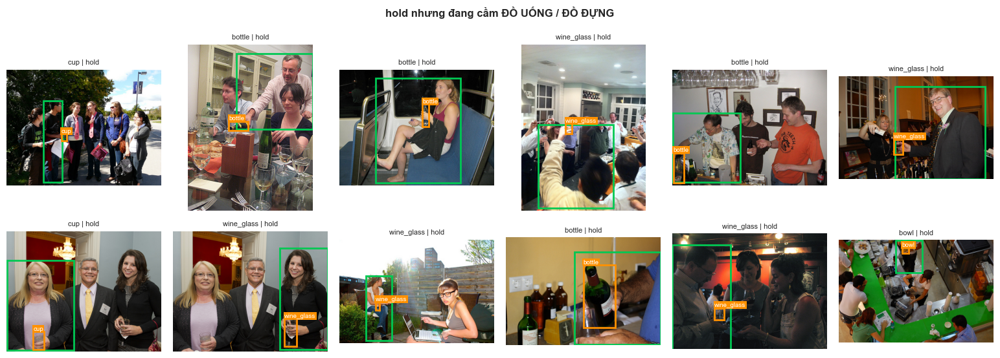

In [26]:
# 3) Cầm đồ ăn / đồ uống nhưng bị xếp vào hold (không có eat/drink)
cam_do_an = df[(df.target_label == 'hold') & df.objects.apply(lambda o: o.get('hold', '') in FOOD)]
cam_do_uong = df[(df.target_label == 'hold') & df.objects.apply(lambda o: o.get('hold', '') in DRINK_CONTAINER)]
print('Đồ ăn  :', cam_do_an.objects.apply(lambda o: o['hold']).value_counts().to_dict())
print('Đồ uống:', cam_do_uong.objects.apply(lambda o: o['hold']).value_counts().to_dict())
xem_nhom(cam_do_an, FOOD, 'hold nhưng đang cầm ĐỒ ĂN', CLASS_COLORS['hold'], n=12)
xem_nhom(cam_do_uong, DRINK_CONTAINER, 'hold nhưng đang cầm ĐỒ UỐNG / ĐỒ ĐỰNG', CLASS_COLORS['hold'], n=12)

**4. Có máy tính nhưng không phải `work_on_computer`**

Đang thuộc nhãn đích: {'unknown': 36, 'hold': 16, 'take_on_phone': 14, 'ride': 3}
Hành động gốc đi kèm máy tính: {'look': 57, 'work_on_computer': 14, 'hold': 13, 'carry': 1}
🔎 Có máy tính nhưng KHÔNG phải work_on_computer  |  69 người


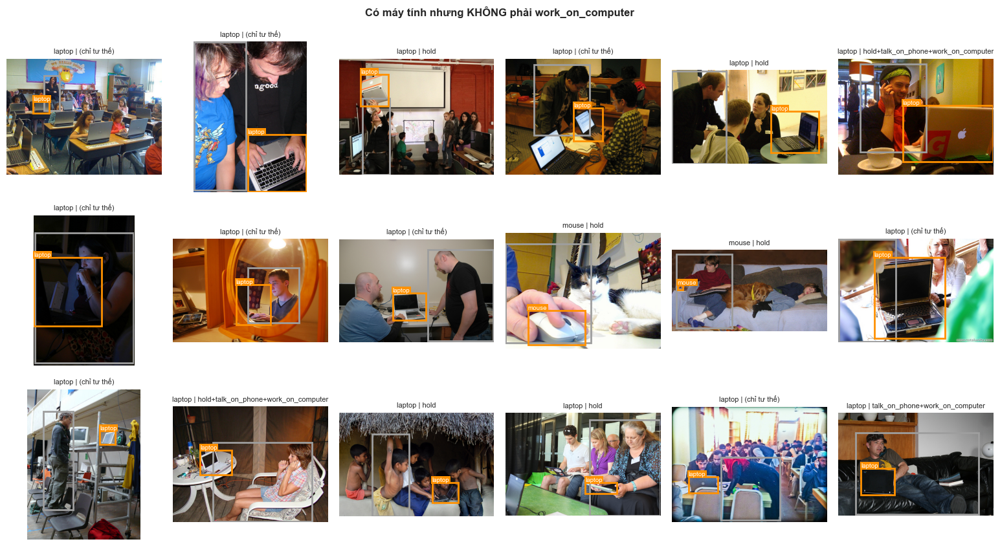

In [27]:
# 4) Có máy tính (laptop / keyboard / mouse) trong bất kỳ hành động nào nhưng KHÔNG thuộc work_on_computer
co_may_tinh = df[df.objects.apply(lambda o: any(v in COMPUTER for v in o.values())) & (df.target_label != 'work_on_computer')]
print('Đang thuộc nhãn đích:', co_may_tinh.target_label.value_counts().to_dict())
print('Hành động gốc đi kèm máy tính:', pd.Series([a for r in co_may_tinh.itertuples() for a, v in r.objects.items() if v in COMPUTER]).value_counts().to_dict())
xem_nhom(co_may_tinh, COMPUTER, 'Có máy tính nhưng KHÔNG phải work_on_computer', CLASS_COLORS['unknown'], n=18)

### 3.3 Nhóm `unknown` gồm những gì?
`unknown` đang trộn 3 kiểu người rất khác nhau. Model sẽ khó học một lớp "linh tinh" như vậy.

In [28]:
def kieu_unknown(acts):
    if len(acts) == 0:
        return '1. không có hành động nào'
    if set(acts) <= POSE_ONLY:
        return '2. chỉ có tư thế (đứng/ngồi/đi/nhìn…)'
    return '3. có tương tác khác (thể thao, cắt, đọc, mang…)'

unk = df[df['target_label'] == 'unknown']
bang_dem(unk['actions'].apply(kieu_unknown), 'kiểu unknown')

,kiểu unknown,số lượng,tỷ lệ %
0,2. chỉ có tư thế (đứng/ngồi/đi/nhìn…),3605,49.7
1,"3. có tương tác khác (thể thao, cắt, đọc, mang…)",3480,48.0
2,1. không có hành động nào,166,2.3


### 3.4 Vật được "cưỡi" (`ride`) là gì?

In [29]:
ride_obj = df[df['target_label'] == 'ride']['objects'].apply(lambda o: o.get('ride', '') or '(không có vật)')
bang_dem(ride_obj, 'vật được cưỡi')

,vật được cưỡi,số lượng,tỷ lệ %
0,motorcycle,284,28.4
1,horse,259,25.9
2,elephant,134,13.4
3,bicycle,110,11.0
4,(không có vật),75,7.5
5,boat,63,6.3
6,train,38,3.8
7,truck,21,2.1
8,car,13,1.3
9,bus,2,0.2


#### 3.4b Xem ảnh `ride` theo nhãn gốc: cưỡi, lái xe, ngồi trong xe
V-COCO chỉ có 1 hành động `ride` cho mọi trường hợp: **cưỡi** (horse, elephant, motorcycle, bicycle), **lái** hoặc **ngồi trong/trên** phương tiện (car, truck, bus, train, boat). Nó **không phân biệt** người lái và hành khách. Dưới đây là ảnh theo từng loại vật được cưỡi, lấy theo nhãn gốc `ride` (không qua priority rule).

phương tiện có mái/khoang (car, truck, bus, train, boat): 147 người
xe hai bánh (motorcycle, bicycle): 409 người
con vật (horse, elephant): 394 người
(không có vật): 94 người
Tổng người có nhãn gốc ride: 1044 

🔎 ride + car  |  20 người


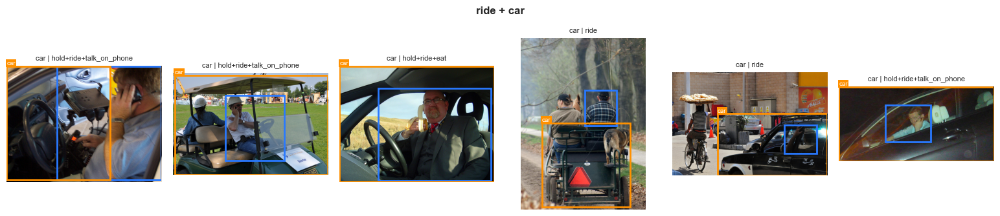

🔎 ride + truck  |  22 người


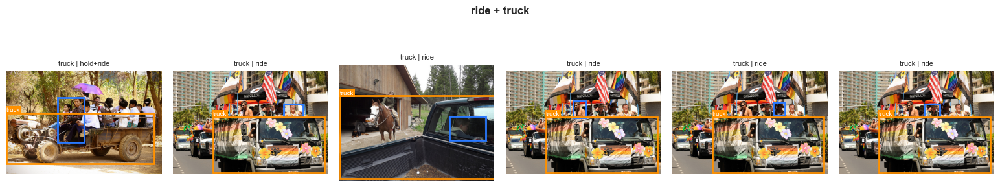

🔎 ride + bus  |  2 người


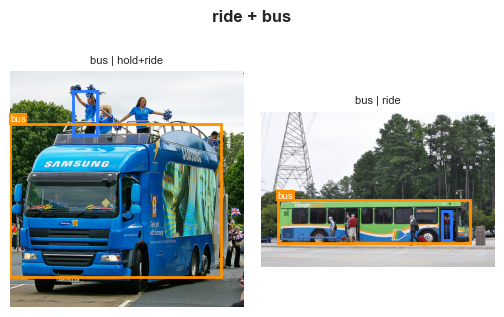

🔎 ride + train  |  39 người


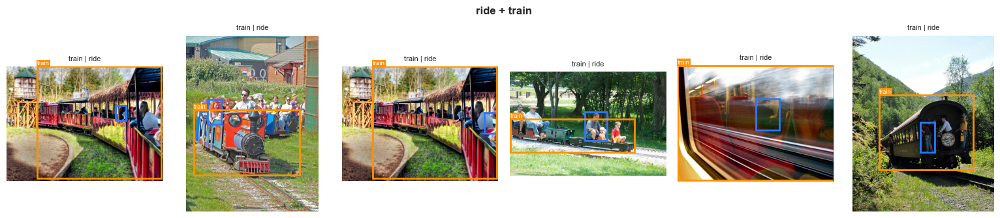

🔎 ride + boat  |  64 người


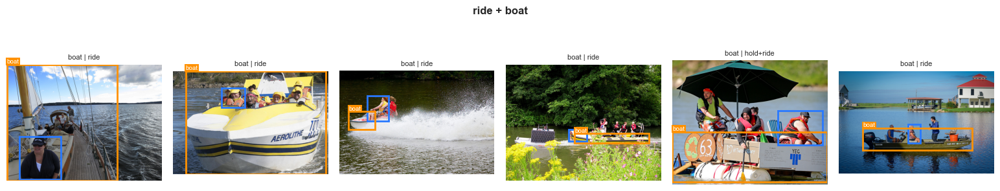

🔎 ride + (không có vật)  |  94 người


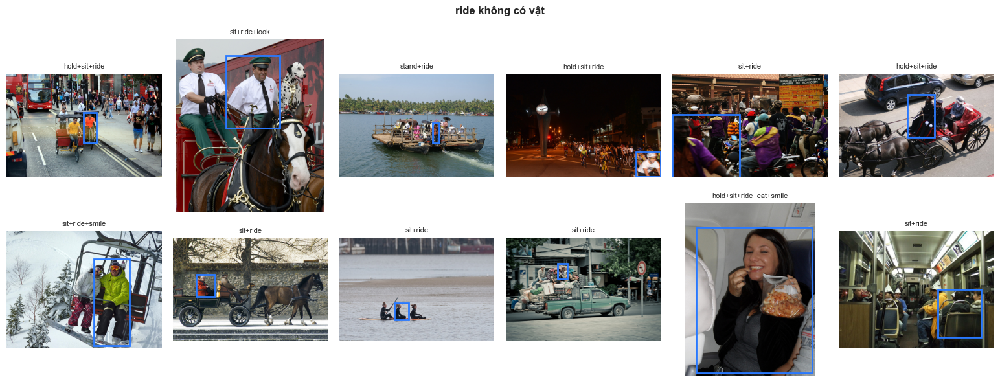

In [38]:
ride_all = df[df.actions.apply(lambda a: 'ride' in a)].copy()
ride_all['vat_ride'] = ride_all.objects.apply(lambda o: o.get('ride', '') or '(không có vật)')

NHOM_RIDE = {'phương tiện có mái/khoang (car, truck, bus, train, boat)': ['car', 'truck', 'bus', 'train', 'boat'],
             'xe hai bánh (motorcycle, bicycle)': ['motorcycle', 'bicycle'],
             'con vật (horse, elephant)': ['horse', 'elephant']}
for ten, ds in NHOM_RIDE.items():
    print(f'{ten}: {ride_all.vat_ride.isin(ds).sum()} người')
print(f'(không có vật): {(ride_all.vat_ride == "(không có vật)").sum()} người')
print('Tổng người có nhãn gốc ride:', len(ride_all), '\n')

# Ảnh: mỗi loại phương tiện 6 người (xe lớn trước, vì đây là chỗ người lái / ngồi trong xe)
for vat in ['car', 'truck', 'bus', 'train', 'boat']:
    xem_nhom(ride_all[ride_all.vat_ride == vat], {vat}, f'ride + {vat}', CLASS_COLORS['ride'], n=6)

# Người ride nhưng V-COCO không khoanh vật nào: xem là đang cưỡi cái gì?
khong_vat = ride_all[ride_all.vat_ride == '(không có vật)']
print('=' * 100)
print(f'🔎 ride + (không có vật)  |  {len(khong_vat)} người')
rows = khong_vat.sample(min(12, len(khong_vat)), random_state=1)
show_grid([{'img': lay_anh(r.image_id), 'title': r.original_label[:48], 'boxes': [(*r.bbox, CLASS_COLORS['ride'], '')]} for r in rows.itertuples()], 'ride không có vật')

### 3.5 1 ảnh có nhiều người mang nhãn đích KHÁC nhau
Nếu training theo **cả ảnh** thì ảnh này không biết gán nhãn gì. Nếu training theo **từng người (crop bbox)** thì không sao.

1508 / 10346 ảnh có ≥2 nhãn đích khác nhau


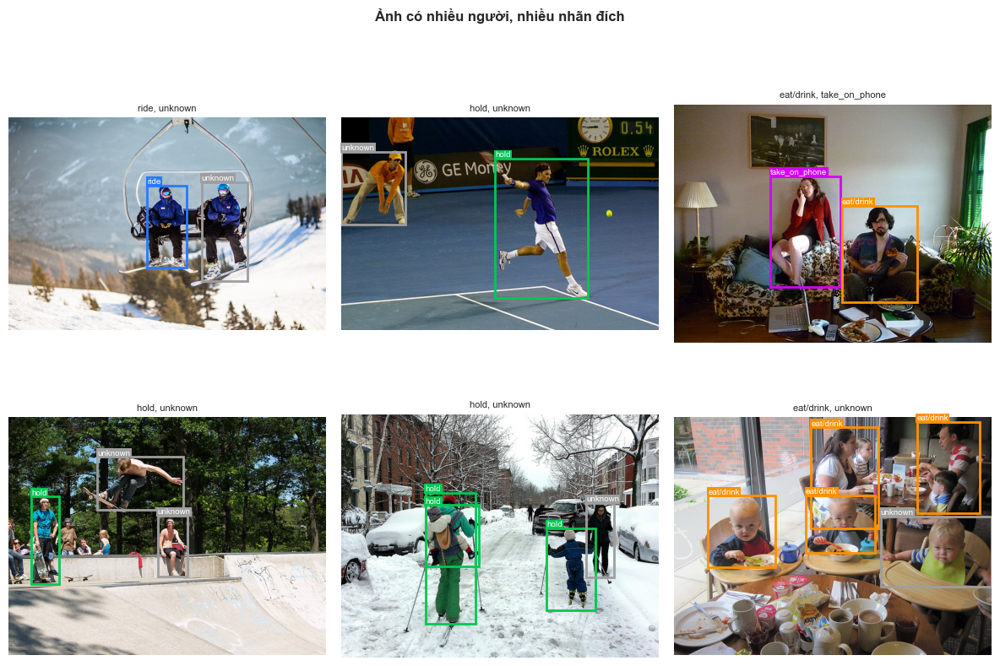

In [30]:
nhan_moi_anh = df.groupby('image_id')['target_label'].nunique()
anh_nhieu_nhan = nhan_moi_anh[nhan_moi_anh > 1].index
print(f'{len(anh_nhieu_nhan)} / {df.image_id.nunique()} ảnh có ≥2 nhãn đích khác nhau')
items = []
for img_id in pd.Series(anh_nhieu_nhan).sample(min(6, len(anh_nhieu_nhan)), random_state=0):
    nguoi = df[df.image_id == img_id]
    items.append({'img': lay_anh(img_id), 'title': ', '.join(sorted(set(nguoi.target_label))),
                  'boxes': [(*r.bbox, CLASS_COLORS[r.target_label], r.target_label) for r in nguoi.itertuples()]})
show_grid(items, 'Ảnh có nhiều người, nhiều nhãn đích', ncols=3, size=4)

📌 **Kết luận phần 3**: các quyết định cần chốt:
- ~97% người `talk_on_phone` và ~98% người `drink` cũng có `hold`, nên **bắt buộc** phải có priority rule.
- ~50% `unknown` là người "có tương tác khác" (thể thao, cắt, mang…), không phải "không làm gì".
- `ride` gồm cả voi, thuyền, tàu hỏa, xe tải; ~7% người `ride` không có vật được gán.
- Người cầm điện thoại/laptop mà chỉ có `hold` (~140 người): chuyển sang `take_on_phone`/`work_on_computer`, hay bỏ?
- `carry`, `read`: thống nhất với HICO-DET và VOC.
- `unknown` nên **tách** hoặc **lọc**: ví dụ chỉ giữ người "chỉ có tư thế" làm `unknown`, bỏ người "có tương tác khác".
- Nên training theo **từng người (crop bbox)**.

## Phần 4: Lớp `hold` quá rộng: dẫn chứng và đề xuất

### 4.1 Dẫn chứng
Ở V-COCO, mỗi người `hold` đều có **tên vật đang cầm**. Ta đếm xem đang cầm những vật gì.

In [31]:
hold_df = df_labels[df_labels['target_label'] == 'hold']
if len(hold_df) == 0:
    print('Lớp hold không có mẫu nào trong bộ này.')
else:
    comp = bang_dem(hold_df['hold_object'].astype(str) + '  |  ' + hold_df['hold_verb'].astype(str),
                    'vật | hành động')
    print(f'Lớp hold có {len(hold_df)} mẫu, gồm {len(comp)} kiểu (vật | hành động) khác nhau')
    top5 = comp['số lượng'].head(5).sum() / len(hold_df) * 100
    print(f'Top-5 kiểu chiếm {top5:.1f}% lớp hold '
          '(càng thấp = càng phân tán = càng khó học)')
    counts = df_labels['target_label'].value_counts()
    nho_nhat = counts[counts > 0].min()
    print(f'hold gấp {counts["hold"] / nho_nhat:.1f} lần lớp nhỏ nhất ({counts.idxmin()}: {nho_nhat})')
    display(comp.head(20))

Lớp hold có 5125 mẫu, gồm 54 kiểu (vật | hành động) khác nhau
Top-5 kiểu chiếm 58.3% lớp hold (càng thấp = càng phân tán = càng khó học)
hold gấp 8.0 lần lớp nhỏ nhất (take_on_phone: 639)


,vật | hành động,số lượng,tỷ lệ %
0,| hold,1485,29.0
1,tennis_racket | hold,526,10.3
2,knife | hold,329,6.4
3,surfboard | hold,324,6.3
4,frisbee | hold,323,6.3
5,baseball_bat | hold,222,4.3
6,suitcase | hold,176,3.4
7,book | hold,170,3.3
8,handbag | hold,136,2.7
9,cell_phone | hold,126,2.5


1485 người hold KHÔNG có vật được gán
69% người hold còn có tương tác khác ngoài tư thế (ví dụ hit, ski, surf, cut, carry…), tức hold chỉ là "phụ"


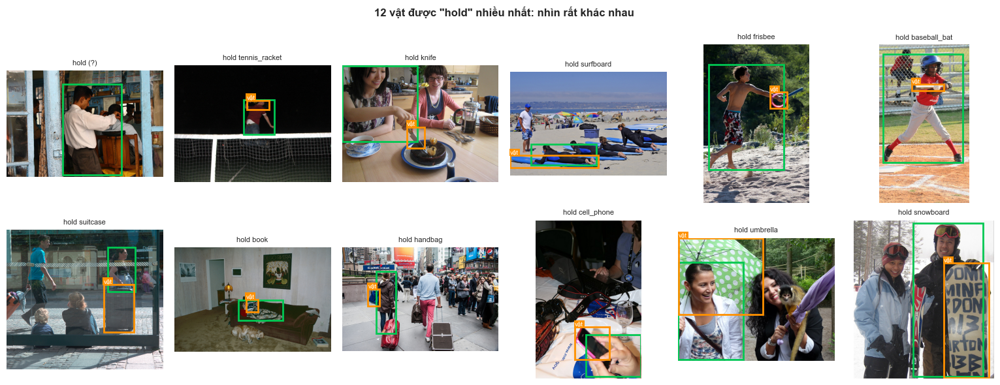

In [32]:
hold_df = df[df['target_label'] == 'hold']
print(f"{(hold_df['hold_object'] == '').sum()} người hold KHÔNG có vật được gán")
tuong_tac_khac = hold_df['actions'].apply(lambda a: len(set(a) - POSE_ONLY - {'hold'}) > 0)
print(f"{tuong_tac_khac.mean() * 100:.0f}% người hold còn có tương tác khác ngoài tư thế "
      '(ví dụ hit, ski, surf, cut, carry…), tức hold chỉ là "phụ"')

# 1 ảnh cho mỗi loại vật phổ biến nhất trong hold
items = []
for obj in hold_df['hold_object'].value_counts().head(12).index:
    r = hold_df[hold_df['hold_object'] == obj].sample(1, random_state=3).iloc[0]
    items.append(item_nguoi(r, f'hold {obj or "(?)"}', CLASS_COLORS['hold']))
show_grid(items, '12 vật được "hold" nhiều nhất: nhìn rất khác nhau', ncols=6)

### 4.2 Ba phương án giới hạn `hold`

| Phương án | Ý tưởng | Đổi nhãn? |
|---|---|---|
| **A. Theo vật thể** | Chỉ giữ `hold` khi vật là **đồ nhỏ cầm tay** (danh sách `HOLD_OBJECTS` bên dưới). Nhạc cụ, ván trượt, vợt, gậy, diều… chuyển sang `unknown` | Có |
| **B. Theo động từ** | Chỉ giữ `hold` khi hành động đúng là **cầm/mang** (`hold`, `carry`). Các hành động "chơi", "chụp", "vung"… chuyển sang `unknown` | Có |
| **C. Cắt số lượng** | Giữ nguyên định nghĩa, chỉ **bớt mẫu `hold`** khi training (tối đa `k` lần lớp nhỏ nhất) | Không, chỉ đổi cách lấy mẫu |

👉 **Khuyến nghị mặc định: A + B**, tức `hold` = *cầm hoặc mang một vật nhỏ bằng tay*. Định nghĩa hẹp và rõ thì model dễ học hơn. **C** để dành cho lúc training (dùng sampler), không dùng để sửa nhãn.

Bạn đổi phương án bằng biến `HOLD_POLICY` ở cell dưới: `None`, `'A'`, `'B'`, `'A+B'`.

In [33]:
HOLD_POLICY = 'A+B'   # 👈 đổi ở đây: None | 'A' | 'B' | 'A+B'

# Đồ vật nhỏ cầm tay (tên theo kiểu COCO, dùng dấu gạch dưới)
HOLD_OBJECTS = {
    'cup', 'bottle', 'wine_glass', 'bowl', 'umbrella', 'handbag', 'backpack', 'suitcase', 'tie',
    'book', 'knife', 'fork', 'spoon', 'scissors', 'remote', 'toothbrush', 'hair_drier',
    'teddy_bear', 'vase', 'camera', 'clock', 'banana', 'apple', 'orange', 'sandwich',
    'hot_dog', 'pizza', 'donut', 'cake', 'carrot', 'broccoli',
}
HOLD_VERBS = {'hold', 'carry'}


def gioi_han_hold(row, policy=HOLD_POLICY):
    """Trả về nhãn mới sau khi áp phương án giới hạn hold cho 1 dòng."""
    lbl = row['target_label']
    if lbl != 'hold' or policy is None:
        return lbl
    obj = str(row.get('hold_object', '')).replace(' ', '_')
    verb = str(row.get('hold_verb', ''))
    if 'A' in policy and obj not in HOLD_OBJECTS:
        return 'unknown'
    if 'B' in policy and verb not in HOLD_VERBS:
        return 'unknown'
    return lbl


def so_sanh_phuong_an(df):
    """Bảng số mẫu 6 lớp: trước và sau từng phương án A, B, A+B, và C (k=3)."""
    out = pd.DataFrame(index=TARGET_CLASSES)
    out['hiện tại'] = df['target_label'].value_counts().reindex(TARGET_CLASSES, fill_value=0)
    for p in ['A', 'B', 'A+B']:
        out[p] = df.apply(lambda r: gioi_han_hold(r, p), axis=1).value_counts().reindex(TARGET_CLASSES, fill_value=0)
    nho_nhat = out['hiện tại'][out['hiện tại'] > 0].min()
    out['C (k=3)'] = out['hiện tại']
    out.loc['hold', 'C (k=3)'] = min(out.loc['hold', 'hiện tại'], 3 * nho_nhat)
    return out

#### 4.2b So sánh: đồ thường ngày có kèm hành động gốc khác không?
Câu hỏi: nếu đồ thể thao bị loại vì "hold chỉ là phụ", thì **đồ thường ngày** (`HOLD_OBJECTS`) có khác không? Bảng đếm theo 3 nhóm vật và theo từng vật, kèm ảnh.

,so_nguoi,co_them_hanh_dong
nhom_vat,,
không có vật,1485,66%
thường ngày,1428,68%
thể thao,1941,84%
vật khác,271,23%


,vật,số người,% có thêm hành động,hành động gốc đi kèm nhiều nhất
0,knife,329,97,cut (318)
1,suitcase,176,79,"carry (139), run (1)"
2,book,170,85,"read (142), carry (3)"
3,handbag,136,72,"carry (97), skateboard (2), read (1)"
4,umbrella,124,80,"carry (95), read (4), run (2)"
5,remote,104,4,"point (2), jump (1), throw (1)"
6,scissors,85,92,"cut (78), read (1)"
7,backpack,84,68,"ski (31), carry (29), skateboard (2)"
8,teddy_bear,36,11,carry (4)
9,cup,36,6,"cut (1), throw (1)"


🔎 hold + knife  |  329 người


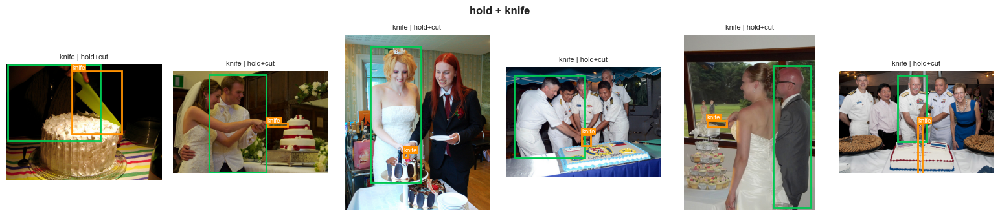

🔎 hold + book  |  170 người


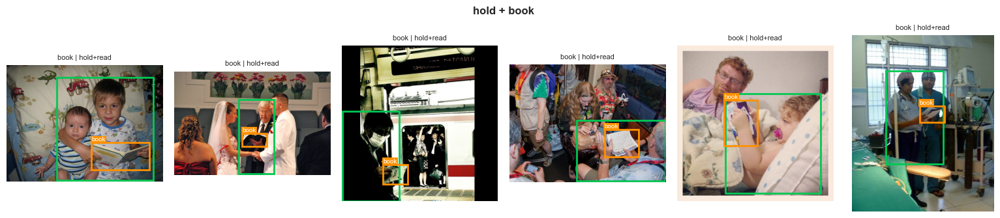

🔎 hold + suitcase  |  176 người


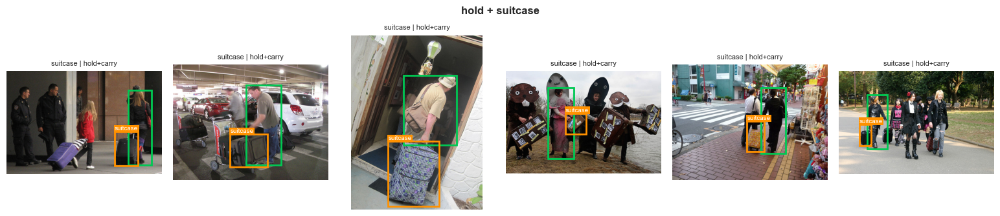

🔎 hold + cell_phone  |  126 người


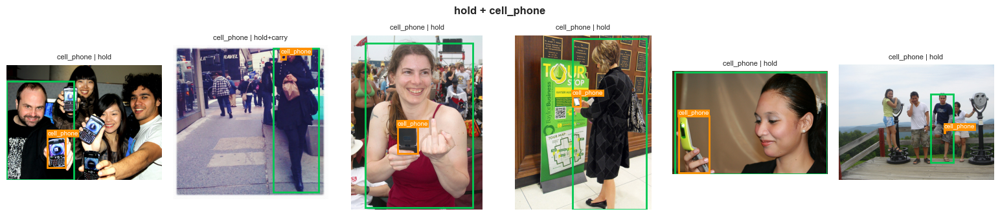

🔎 hold + remote  |  104 người


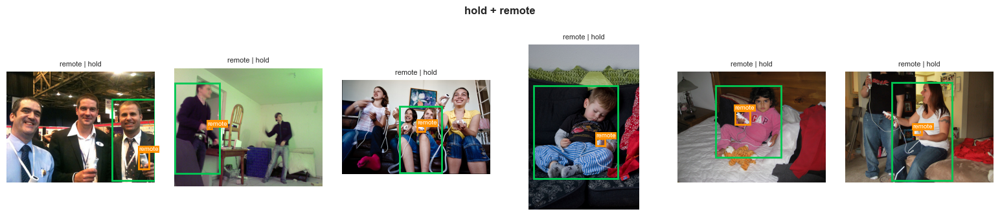

In [34]:
hold_all = df[df.target_label == 'hold'].copy()
hold_all['vat'] = hold_all.objects.apply(lambda o: o.get('hold', ''))
hold_all['hanh_dong_them'] = hold_all.actions.apply(lambda a: [x for x in a if x != 'hold' and x not in POSE])
hold_all['nhom_vat'] = hold_all.vat.apply(lambda v: 'không có vật' if v == '' else ('thể thao' if v in SPORT_OBJECTS else ('thường ngày' if v in HOLD_OBJECTS else 'vật khác')))

# 1) Tỉ lệ có thêm hành động gốc, theo nhóm vật
tong = hold_all.groupby('nhom_vat').agg(so_nguoi=('vat', 'size'), co_them_hanh_dong=('hanh_dong_them', lambda s: (s.apply(len) > 0).mean()))
tong['co_them_hanh_dong'] = (tong['co_them_hanh_dong'] * 100).round(0).astype(int).astype(str) + '%'
display(tong)

# 2) Từng vật thường ngày: hành động gốc đi kèm
bang = []
for vat, g in hold_all[hold_all.nhom_vat == 'thường ngày'].groupby('vat'):
    dem = pd.Series([x for l in g.hanh_dong_them for x in l]).value_counts()
    bang.append({'vật': vat, 'số người': len(g), '% có thêm hành động': round((g.hanh_dong_them.apply(len) > 0).mean() * 100),
                 'hành động gốc đi kèm nhiều nhất': ', '.join(f'{k} ({v})' for k, v in dem.head(3).items())})
display(pd.DataFrame(bang).sort_values('số người', ascending=False).head(15).reset_index(drop=True))

# 3) Ảnh: vật có hành động đi kèm rõ (knife, book, suitcase) và vật hầu như không có (cell_phone, remote)
for vat in ['knife', 'book', 'suitcase', 'cell_phone', 'remote']:
    xem_nhom(hold_all[hold_all.vat == vat], {vat}, f'hold + {vat}', CLASS_COLORS['hold'], n=6)

,hiện tại,A,B,A+B,C (k=3)
hold,5125,1428,5125,1428,1917
ride,999,999,999,999,999
eat/drink,1334,1334,1334,1334,1334
take_on_phone,639,639,639,639,639
work_on_computer,851,851,851,851,851
unknown,7251,10948,7251,10948,7251


ℹ️ Ở V-COCO, hành động của hold luôn là "hold" nên phương án B không thay đổi gì. Phương án A mới có tác dụng.
Phương án A+B: 3697 người bị đẩy ra khỏi hold. Vật bị loại nhiều nhất:


,vật,số lượng,tỷ lệ %
0,(không có vật),1485,40.2
1,tennis_racket,526,14.2
2,surfboard,324,8.8
3,frisbee,323,8.7
4,baseball_bat,222,6.0
5,cell_phone,126,3.4
6,snowboard,114,3.1
7,skis,106,2.9
8,baseball_glove,104,2.8
9,sports_ball,98,2.7


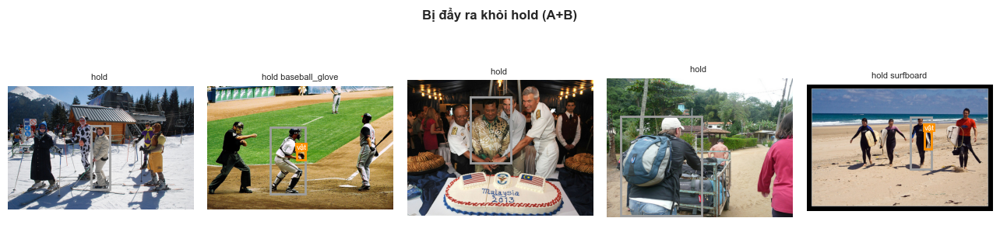

In [35]:
display(so_sanh_phuong_an(df_labels))
print('ℹ️ Ở V-COCO, hành động của hold luôn là "hold" nên phương án B không thay đổi gì. Phương án A mới có tác dụng.')
df_labels['target_label_hold_limited'] = df_labels.apply(gioi_han_hold, axis=1)

bi_day = df[(df_labels['target_label'] == 'hold') & (df_labels['target_label_hold_limited'] != 'hold')]
print(f'Phương án {HOLD_POLICY}: {len(bi_day)} người bị đẩy ra khỏi hold. Vật bị loại nhiều nhất:')
display(bang_dem(bi_day['hold_object'].replace('', '(không có vật)'), 'vật').head(10))
show_grid([item_nguoi(r, f'hold {r.hold_object}', '#9E9E9E') for r in bi_day.sample(min(5, len(bi_day)), random_state=0).itertuples()],
          f'Bị đẩy ra khỏi hold ({HOLD_POLICY})', ncols=5)

In [36]:
df_labels.to_csv('labels_6class_v_coco.csv', index=False)
print('💾 Đã lưu', os.path.abspath('labels_6class_v_coco.csv'), df_labels.shape)

💾 Đã lưu /Users/dacleba/Documents/Experiment_thị_giác_máy_tính/lebadac/human-object-interaction-recognition/EDA/v-coco/v-coco/labels_6class_v_coco.csv (16199, 10)


📌 **Kết luận phần 4**
- `hold` của V-COCO có ~5.100 người, 50+ loại vật, top-5 chỉ chiếm ~58%, tức rất phân tán.
- ~69% người `hold` còn có tương tác khác (đánh bóng, lướt ván, cắt…), tức `hold` thường chỉ là hành động "phụ".
- ~29% người `hold` **không có vật được gán**; vật phổ biến nhất lại là **vợt tennis, ván lướt, đĩa frisbee, gậy bóng chày**, không phải đồ cầm tay thường ngày.
- Phương án **A** giảm `hold` từ ~5.100 xuống ~1.400 (còn dao, vali, sách, túi, ô, remote…), hẹp và rõ hơn nhiều. Đổi lại, `unknown` phình to hơn.
- V-COCO là nguồn `hold` lớn nhất, nên định nghĩa ở đây ảnh hưởng mạnh nhất tới model.

## Phụ lục: Xem ảnh GỐC theo nhãn gốc của V-COCO

V-COCO gốc có **26 hành động**. Cell bên dưới chép **nguyên ảnh COCO gốc (không cắt, không vẽ khung)** vào **folder cùng tên hành động gốc** (ví dụ `hold/`, `ride/`, `talk_on_phone/`), không map, không dịch.

- V-COCO gán nhãn cho **từng người**, còn ảnh có thể có nhiều người. Nên một ảnh nằm trong folder `X` nếu **có ít nhất 1 người** trong ảnh có hành động `X`. Ảnh có nhiều hành động sẽ nằm trong nhiều folder.
- Tên file: `<image_id>__<các hành động có trong ảnh>.jpg`, để biết ảnh đó còn có những hành động nào khác.
- Ảnh không có người nào mang hành động nào nằm trong `_khong_co_hanh_dong/`.
- `MAX_MOI_NHAN` = số ảnh tối đa mỗi folder (đặt `None` để lưu hết, phải tải hơn 10 nghìn ảnh COCO nên lâu).

In [37]:
import shutil

OUT_DIR = 'vcoco_theo_nhan_goc'   # folder kết quả
MAX_MOI_NHAN = 150                # số ảnh tối đa mỗi nhãn gốc. None = lưu hết

# Với mỗi ảnh: gom tất cả hành động gốc của mọi người trong ảnh
hd_moi_anh = df.groupby('image_id')['actions'].apply(lambda ls: sorted({a for acts in ls for a in acts}))

def chep_anh(image_id, folder):
    lay_anh(image_id)                          # đảm bảo đã tải về coco_images/
    src = f'coco_images/{image_id}.jpg'
    if not os.path.exists(src):
        return False
    ten_hd = '+'.join(hd_moi_anh[image_id]) or 'none'
    os.makedirs(f'{OUT_DIR}/{folder}', exist_ok=True)
    shutil.copy(src, f'{OUT_DIR}/{folder}/{image_id}__{ten_hd[:100]}.jpg')   # chép nguyên file, không cắt
    return True

for act in ACTIONS + ['_khong_co_hanh_dong']:
    if act == '_khong_co_hanh_dong':
        ids = [i for i, h in hd_moi_anh.items() if len(h) == 0]
    else:
        ids = [i for i, h in hd_moi_anh.items() if act in h]
    if MAX_MOI_NHAN is not None and len(ids) > MAX_MOI_NHAN:
        ids = random.Random(42).sample(ids, MAX_MOI_NHAN)
    n = sum(chep_anh(i, act) for i in ids)
    print(f'{act:22s}: đã lưu {n} ảnh')

print('💾 Xong. Mở folder:', os.path.abspath(OUT_DIR))

hold                  : đã lưu 150 ảnh
stand                 : đã lưu 150 ảnh
sit                   : đã lưu 150 ảnh
ride                  : đã lưu 150 ảnh
walk                  : đã lưu 150 ảnh
look                  : đã lưu 150 ảnh
hit                   : đã lưu 150 ảnh
eat                   : đã lưu 150 ảnh
jump                  : đã lưu 150 ảnh
lay                   : đã lưu 150 ảnh
talk_on_phone         : đã lưu 150 ảnh
carry                 : đã lưu 150 ảnh
throw                 : đã lưu 150 ảnh
catch                 : đã lưu 150 ảnh
cut                   : đã lưu 150 ảnh
run                   : đã lưu 150 ảnh
work_on_computer      : đã lưu 150 ảnh
ski                   : đã lưu 150 ảnh
surf                  : đã lưu 150 ảnh
skateboard            : đã lưu 150 ảnh
smile                 : đã lưu 150 ảnh
drink                 : đã lưu 150 ảnh
kick                  : đã lưu 150 ảnh
point                 : đã lưu 64 ảnh
read                  : đã lưu 150 ảnh
snowboard             : đã